# Galaxy-galaxy lensing with Euclid Flagship mocks: a tutorial

This notebook walks through a small, end-to-end measurement of the excess surface
density $\Delta\Sigma(R)$ around Euclid Flagship2 mock galaxies with `weaklens_pipeline`:

1. Query a random 1/256 subsample of the Flagship2 mock on [CosmoHub](https://cosmohub.pic.es/catalogs/353)
2. Download the query results with `wget`
3. Convert them into the file layout read by `weaklens_select.py`
4. Write a configuration and run `weaklens_aroundsource.py`
5. Read and plot the output `Dsigma.dat`
6. Scale up to the full footprint

We use the full Flagship2 footprint (one octant, about 5000 deg$^2$) but keep only 1/256 of
the galaxies, with one lens bin at $0.9 < z < 1.1$. This keeps the downloads small and the
measurement to a few minutes on a single core. It is meant to show how the pieces fit
together, not to give a science-grade measurement: the sparse sampling makes the signal
noisy, in particular at small $R$ where there are few pairs.

You also need a CosmoHub account with access to the Euclid Flagship2 mock catalogue.

## Setup (run once, in a terminal)

From the repository root, run

```bash
bash notebooks/setup_weaklens_env.sh
```

The script ([`setup_weaklens_env.sh`](setup_weaklens_env.sh)) does four things:

1. creates a conda environment `weaklens_pipeline_tutorial` (conda-forge) with Python 3.10, `numpy<2`, SWIG 3.0.12,
   GSL, Boost, `gpg` and the Python packages used in this notebook;
2. `pip install -r requirements.txt`;
3. builds and installs the pipeline with `python setup.py install`, pointing the compiler and
   the runtime linker to GSL and Boost inside the environment (and allowing the deprecated
   `boost/timer.hpp` header, which Boost >= 1.84 otherwise rejects);
4. registers the environment as the Jupyter kernel **"Python (weaklens_pipeline_tutorial)"**.

The version pins matter: the bundled `src/numpy.i` relies on Python-2 compatibility macros
that SWIG 4 no longer generates, and `numpy<2` keeps the old NumPy C API it uses.

Then open this notebook in Jupyter or VS Code and select the kernel "Python (weaklens_pipeline_tutorial)".
To use a different environment name, pass it as an argument:
`bash notebooks/setup_weaklens_env.sh myenv`.

### Manual setup

If you cannot run the script, type the same steps in a terminal, starting from the repository
root. The grey cells below are plain text (not executed by the notebook), so they can be copied
as they are.

**Step 1.** Create and activate the conda environment:

**Step 2.** Install the remaining Python requirements:

**Step 3.** Build and install the pipeline, then check that it imports. If the check fails with
`No module named weaklens`, run the `python setup.py install` line once more.

**Step 4.** Register the Jupyter kernel. `conda run` makes sure the kernel points to the
Python of `weaklens_pipeline_tutorial` even if another environment is active:

In VS Code, choose *Select Kernel* → *Select Another Kernel* → *Jupyter Kernel...* →
"Python (weaklens_pipeline_tutorial)". If it is not listed, run *Developer: Reload Window*
from the command palette and try again.

## 0. Settings

`PIPELINE_DIR` is the repository root (this notebook lives in `notebooks/`). All data and
outputs go under `DATA_DIR`. The sampling rate and the redshift selections are defined
here and reused in the SQL queries below.

In [ ]:
import os
import sys
import numpy as np
import yaml
import fitsio
import matplotlib.pyplot as plt

PIPELINE_DIR = os.path.abspath("..")
sys.path.insert(0, PIPELINE_DIR)

DATA_DIR = os.path.abspath("flagship_tutorial_data")
os.makedirs(DATA_DIR, exist_ok=True)

# Keep 1 out of N_BUCKETS galaxies (Hive TABLESAMPLE on CosmoHub)
N_BUCKETS = 256

# Area of the Flagship2 octant [deg^2] (roughly 145 < RA < 235, 0 < Dec < 90)
AREA_DEG2 = 5157.0

# Lens bin (in true redshift) and source selection (in photo-z)
ZL_MIN, ZL_MAX = 0.9, 1.1
ZS_PHOT_MIN, ZS_PHOT_MAX = 1.3, 2.5

## 1. Query the Flagship2 mock on CosmoHub

Log in to CosmoHub, open the Euclid Flagship2 catalogue (`euclid_fs2_mock_dr_v1_1_phz` at the
time of writing), choose a custom SQL query, and submit the two queries printed by the cell
below. Choose **FITS** as the output format.

`TABLESAMPLE (BUCKET 1 OUT OF N)` keeps one of $N$ hash buckets of the table and goes right
after the table name, before `WHERE`. Check in section 3 that the sampled galaxies cover the
whole footprint uniformly: if the table is bucketed on a sky-position column, a bucket is a
set of sky regions rather than a random subsample.

**Lenses**: H$\alpha$ emitters above the Euclid spectroscopic flux limit
($\log_{10} f_{\mathrm{H}\alpha} > -15.699$ with the model-3 H$\alpha$ flux,
`logf_halpha_model3_ext`), selected in true redshift.

**Sources**: galaxies with intrinsic ellipticities and shears, brighter than
$\mathrm{VIS} < 24.5$, with photo-z behind the lens bin. The VIS magnitude is computed from
the flux in erg s$^{-1}$ cm$^{-2}$ Hz$^{-1}$ as $-2.5\log_{10} f - 48.6$.

In [5]:
sample = f"TABLESAMPLE (BUCKET 1 OUT OF {N_BUCKETS})"

lens_query = f'''SELECT `halo_id`, `galaxy_id`, `ra_gal`, `dec_gal`, `observed_redshift_gal`, `true_redshift_gal`
FROM euclid_fs2_mock_dr_v1_1_phz {sample}
WHERE `true_redshift_gal` > {ZL_MIN} AND `true_redshift_gal` < {ZL_MAX}
  AND `logf_halpha_model3_ext` > -15.699'''

source_query = f'''SELECT `halo_id`, `galaxy_id`, `ra_gal`, `dec_gal`, `phz_mode_1`, `true_redshift_gal`,
       `eps1_gal`, `eps2_gal`, `gamma1`, `gamma2`
FROM euclid_fs2_mock_dr_v1_1_phz {sample}
WHERE `eps1_gal` IS NOT NULL AND `eps2_gal` IS NOT NULL
  AND `gamma1` IS NOT NULL AND `gamma2` IS NOT NULL
  AND (-2.5 * LOG10(`euclid_vis_el_model3_ext_odonnell_ext`) - 48.6) < 24.5
  AND `phz_mode_1` > {ZS_PHOT_MIN} AND `phz_mode_1` < {ZS_PHOT_MAX}'''

print("-- Lens query\n" + lens_query + "\n")
print("-- Source query\n" + source_query)

-- Lens query
SELECT `halo_id`, `galaxy_id`, `ra_gal`, `dec_gal`, `observed_redshift_gal`, `true_redshift_gal`
FROM euclid_fs2_mock_dr_v1_1_phz TABLESAMPLE (BUCKET 1 OUT OF 256)
WHERE `true_redshift_gal` > 0.9 AND `true_redshift_gal` < 1.1
  AND `logf_halpha_model3_ext` > -15.699

-- Source query
SELECT `halo_id`, `galaxy_id`, `ra_gal`, `dec_gal`, `phz_mode_1`, `true_redshift_gal`,
       `eps1_gal`, `eps2_gal`, `gamma1`, `gamma2`
FROM euclid_fs2_mock_dr_v1_1_phz TABLESAMPLE (BUCKET 1 OUT OF 256)
WHERE `eps1_gal` IS NOT NULL AND `eps2_gal` IS NOT NULL
  AND `gamma1` IS NOT NULL AND `gamma2` IS NOT NULL
  AND (-2.5 * LOG10(`euclid_vis_el_model3_ext_odonnell_ext`) - 48.6) < 24.5
  AND `phz_mode_1` > 1.3 AND `phz_mode_1` < 2.5


## 2. Download the results

When a request has finished, CosmoHub lists it with a download link. Copy the link of each
file into the cell below and set `DOWNLOAD = True`. If CosmoHub delivers a compressed file,
decompress it so that `lens_raw.fits` and `source_raw.fits` are plain FITS tables. (If the link
requires a logged-in browser session, download the files from the browser instead and place
them at the same paths.)

In [7]:
DOWNLOAD = False
LENS_URL = "PASTE_THE_LENS_DOWNLOAD_LINK_HERE"
SOURCE_URL = "PASTE_THE_SOURCE_DOWNLOAD_LINK_HERE"

lens_raw = os.path.join(DATA_DIR, "lens_raw.fits")
source_raw = os.path.join(DATA_DIR, "source_raw.fits")

if DOWNLOAD:
    !wget -q -O {lens_raw} "{LENS_URL}"
    !wget -q -O {source_raw} "{SOURCE_URL}"

for f in (lens_raw, source_raw):
    if not os.path.exists(f):
        raise FileNotFoundError(f"{f} not found: run the queries in section 1 and download the results")
    print(f, fitsio.FITS(f)[1].get_nrows(), "rows")

/path/to/weaklens_pipeline/notebooks/flagship_tutorial_data/lens_raw.fits 13879 rows
/path/to/weaklens_pipeline/notebooks/flagship_tutorial_data/source_raw.fits 318950 rows


## 3. Convert to the pipeline's input layout

The `Euclid_Flagship_LightCone` readers in `weaklens_select.py` expect

* lenses: `<lens dir>/lens_bin_<N>.fits` with columns `ra_gal`, `dec_gal`, `true_redshift_gal`
* sources: `<source dir>/source_bin_<N>.fits` with columns `ra_gal`, `dec_gal`,
  `true_redshift_gal`, `eps1_gal`, `eps2_gal`, `gamma1`, `gamma2`

Our queries already applied the bin selections, so each download becomes one bin file.
The pipeline uses `true_redshift_gal` as the lens and source redshift.

In [8]:
lens_dir = os.path.join(DATA_DIR, "lens_bins")
source_dir = os.path.join(DATA_DIR, "source_bins")
os.makedirs(lens_dir, exist_ok=True)
os.makedirs(source_dir, exist_ok=True)

lens = fitsio.read(lens_raw)
source = fitsio.read(source_raw)
# guard against padded column names in the downloaded tables
lens.dtype.names = [n.strip() for n in lens.dtype.names]
source.dtype.names = [n.strip() for n in source.dtype.names]

fitsio.write(os.path.join(lens_dir, "lens_bin_1.fits"), lens, clobber=True)
fitsio.write(os.path.join(source_dir, "source_bin_1.fits"), source, clobber=True)

print(f"lenses : {len(lens):8d}  ({len(lens) / AREA_DEG2:.1f} per deg^2, "
      f"{len(lens) * N_BUCKETS / AREA_DEG2:.0f} per deg^2 before sampling)")
print(f"sources: {len(source):8d}  ({len(source) / AREA_DEG2 / 3600:.3f} per arcmin^2, "
      f"{len(source) * N_BUCKETS / AREA_DEG2 / 3600:.1f} per arcmin^2 before sampling)")

lenses :    13879  (2.7 per deg^2, 689 per deg^2 before sampling)
sources:   318950  (0.017 per arcmin^2, 4.4 per arcmin^2 before sampling)


A quick look at the samples: positions (they should fill the octant uniformly), redshift
distributions, and the source ellipticities.
The observed ellipticity used by the pipeline is $e = \epsilon_{\rm int} + \gamma$
(weak-lensing limit), with a fixed per-component shape noise $e_{\rm rms} = 0.25$ and unit
weights.

std(e1) = 0.264, std(e2) = 0.263


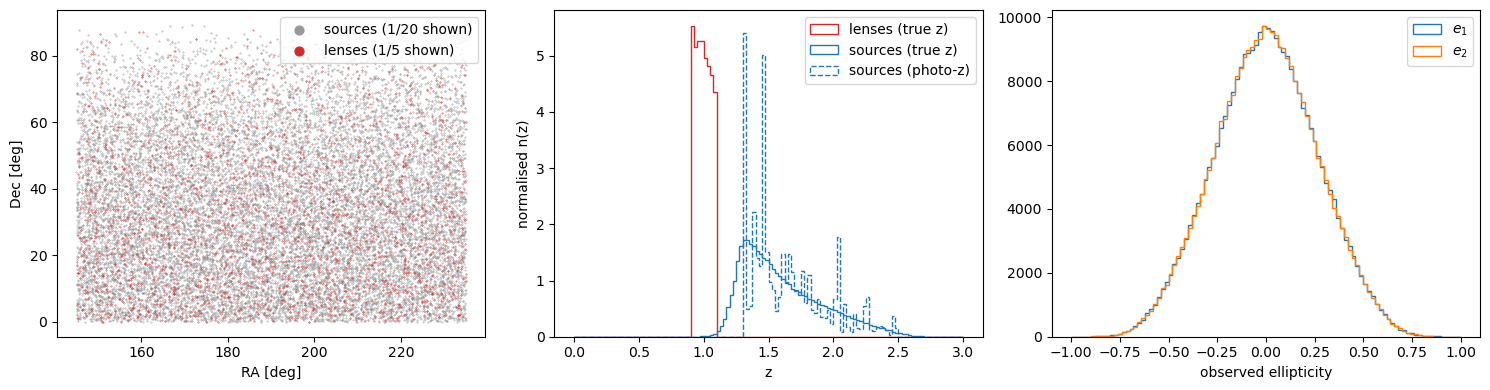

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

ax = axes[0]
ax.scatter(source["ra_gal"][::20], source["dec_gal"][::20], s=0.1, c="0.6", label="sources (1/20 shown)")
ax.scatter(lens["ra_gal"][::5], lens["dec_gal"][::5], s=0.1, c="C3", label="lenses (1/5 shown)")
ax.set_xlabel("RA [deg]"); ax.set_ylabel("Dec [deg]"); ax.legend(markerscale=20, loc="upper right")

ax = axes[1]
bins = np.linspace(0, 3, 121)
ax.hist(lens["true_redshift_gal"], bins=bins, histtype="step", density=True, color="C3", label="lenses (true z)")
ax.hist(source["true_redshift_gal"], bins=bins, histtype="step", density=True, color="C0", label="sources (true z)")
ax.hist(source["phz_mode_1"], bins=bins, histtype="step", density=True, color="C0", ls="--", label="sources (photo-z)")
ax.set_xlabel("z"); ax.set_ylabel("normalised n(z)"); ax.legend()

ax = axes[2]
e1 = source["eps1_gal"] + source["gamma1"]
e2 = source["eps2_gal"] + source["gamma2"]
ax.hist(e1, bins=100, range=(-1, 1), histtype="step", label="$e_1$")
ax.hist(e2, bins=100, range=(-1, 1), histtype="step", label="$e_2$")
ax.set_xlabel("observed ellipticity"); ax.legend()
print(f"std(e1) = {e1.std():.3f}, std(e2) = {e2.std():.3f}")

plt.tight_layout()

Sources whose true redshift lies in front of a lens still enter through the photo-z
selection; the pipeline only uses pairs with $z_s > z_l + {\tt zdiff}$ (in true redshift),
so they do not contribute.

In [10]:
frac_behind = np.mean(source["true_redshift_gal"] > ZL_MAX)
print(f"fraction of sources with true z > {ZL_MAX}: {frac_behind:.3f}")

fraction of sources with true z > 1.1: 0.997


## 4. Configure and run the pipeline

The configuration is a YAML file (a Python dict here). Key entries:

| key | meaning |
|---|---|
| `rmin`, `rmax`, `rbin` | radial bins in comoving $h^{-1}$Mpc (log-spaced) |
| `Omegam` | $\Omega_m$ used for distances (Flagship2: 0.319) |
| `lens.type`, `source.type` | `Euclid_Flagship_LightCone` selects the Flagship readers |
| `lens.lens_bin_id`, `source.source_bin_id` | which `*_bin_<N>.fits` file to read |
| `source.include_corrections: False` | no multiplicative/additive bias corrections (mock shears) |
| `source.fullpofz: False`, `zdiff` | use a point redshift; keep pairs with $z_s > z_l + {\tt zdiff}$ |

For Euclid source types the pipeline uses weaklens *version 3*: no shear-responsivity or
selection-bias correction is applied.

We measure out to $R = 100\,h^{-1}$Mpc (about 2.5 deg at $z \simeq 1$). With 1/256 of the
lenses, the innermost bins contain few pairs, so we start at $0.5\,h^{-1}$Mpc.

In [11]:
outdir = os.path.join(DATA_DIR, "result")
config = {
    "rmin": 0.5,
    "rmax": 100.0,
    "rbin": 12,
    "Omegam": 0.319,
    "lens": {
        "type": "Euclid_Flagship_LightCone",
        "dir": lens_dir,
        "lens_bin_id": 1,
    },
    "source": {
        "type": "Euclid_Flagship_LightCone",
        "dir": source_dir,
        "source_bin_id": 1,
        "filetype": "fits",
        "include_corrections": False,
        "fullpofz": False,
        "zdiff": 0.0,
    },
    "outputdir": outdir,
}

config_path = os.path.join(DATA_DIR, "config_flagship_tutorial.yaml")
with open(config_path, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)
print(open(config_path).read())

rmin: 0.5
rmax: 100.0
rbin: 12
Omegam: 0.319
lens:
  type: Euclid_Flagship_LightCone
  dir: /path/to/weaklens_pipeline/notebooks/flagship_tutorial_data/lens_bins
  lens_bin_id: 1
source:
  type: Euclid_Flagship_LightCone
  dir: /path/to/weaklens_pipeline/notebooks/flagship_tutorial_data/source_bins
  source_bin_id: 1
  filetype: fits
  include_corrections: false
  fullpofz: false
  zdiff: 0.0
outputdir: /path/to/weaklens_pipeline/notebooks/flagship_tutorial_data/result



`run_pipeline` builds a KD-tree of the lenses, then reads the sources in chunks of
$10^6$ and, for every source, accumulates the tangential shear of all lenses within
`rmax`. The same run from the command line is

```
python weaklens_aroundsource.py --config flagship_tutorial_data/config_flagship_tutorial.yaml
```

This takes a few minutes for the 1/256 subsample.

In [12]:
%%time
from weaklens_aroundsource import run_pipeline

with open(config_path) as f:
    cfg = yaml.safe_load(f)
run_pipeline(cfg)

{'type': 'Euclid_Flagship_LightCone', 'dir': '/path/to/weaklens_pipeline/notebooks/flagship_tutorial_data/lens_bins', 'lens_bin_id': 1}
Number of lenses (Euclid Flagship LightCone): 13879
rearranging
Tree done 0.0 seconds
Number of sources (Euclid Flagship LightCone bin 1): rows 0-318950 of 318950
Read 
 318950

 Passed: 
CPU times: user 4.08 s, sys: 65.7 ms, total: 4.15 s
Wall time: 4.16 s


-3.010300e-01 2.000000e+00 1.917525e-01
-3.010300e-01 2.000000e+00 1.917525e-01


## 5. Read and plot $\Delta\Sigma(R)$

`Dsigma.dat` has one row per radial bin. The columns used most often:

| column | content |
|---|---|
| 0 | $\log_{10}$ of the bin centre, $R$ in comoving $h^{-1}$Mpc |
| 5 | $\Delta\Sigma$ (tangential) in $h\,M_\odot\,{\rm pc}^{-2}$ (comoving) |
| 8 | $\Delta\Sigma_\times$ (cross component; should be consistent with zero) |
| 11, 12 | shape-noise errors on columns 5 and 8 |
| 13 | number of lens-source pairs |

The shape-noise error has no sample-variance contribution, so it underestimates the
uncertainty, especially at large $R$. Use jackknife or mock realisations for real
error bars.

In [13]:
res = np.loadtxt(os.path.join(outdir, "Dsigma.dat"))
R = 10 ** res[:, 0]
dsig, dsig_x = res[:, 5], res[:, 8]
err, err_x = res[:, 11], res[:, 12]
npairs = res[:, 13]

print(f"{'R [Mpc/h]':>10} {'DSigma':>10} {'err':>9} {'DSigma_x':>10} {'Npairs':>12}")
for row in zip(R, dsig, err, dsig_x, npairs):
    print("{:10.3f} {:10.3f} {:9.3f} {:10.3f} {:12.0f}".format(*row))

 R [Mpc/h]     DSigma       err   DSigma_x       Npairs
     0.624      1.712    15.537     -1.986          595
     0.970     -9.427     9.453      5.850         1482
     1.508     -7.761     5.967      0.488         3619
     2.345     -7.775     3.847      1.452         8564
     3.646      0.243     2.460      2.101        20789
     5.670     -1.623     1.592      1.158        50224
     8.818     -0.182     1.029      0.001       120328
    13.712     -0.945     0.660      0.063       291903
    21.324     -0.062     0.426     -0.341       702885
    33.160      0.103     0.275     -0.081      1693801
    51.567      0.101     0.177      0.101      4063652
    80.191     -0.058     0.115     -0.005      9701524


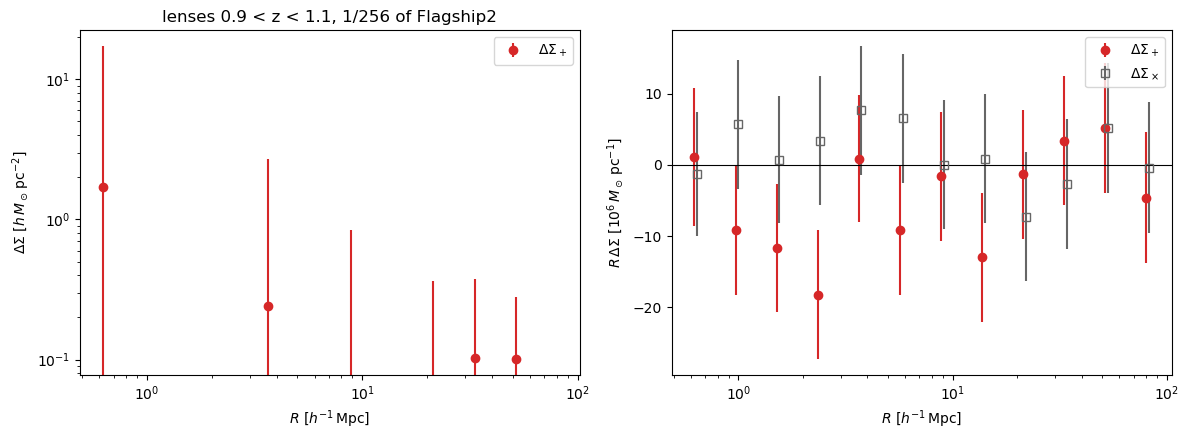

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

ax = axes[0]
ax.errorbar(R, dsig, err, fmt="o", color="C3", label=r"$\Delta\Sigma_+$")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel(r"$R\ [h^{-1}\,{\rm Mpc}]$")
ax.set_ylabel(r"$\Delta\Sigma\ [h\,M_\odot\,{\rm pc}^{-2}]$")
ax.set_title(f"lenses {ZL_MIN} < z < {ZL_MAX}, 1/{N_BUCKETS} of Flagship2")
ax.legend()

ax = axes[1]
ax.errorbar(R, R * dsig, R * err, fmt="o", color="C3", label=r"$\Delta\Sigma_+$")
ax.errorbar(R * 1.03, R * dsig_x, R * err_x, fmt="s", mfc="none", color="0.4", label=r"$\Delta\Sigma_\times$")
ax.axhline(0, color="k", lw=0.8)
ax.set_xscale("log")
ax.set_xlabel(r"$R\ [h^{-1}\,{\rm Mpc}]$")
ax.set_ylabel(r"$R\,\Delta\Sigma\ [10^6\,M_\odot\,{\rm pc}^{-1}]$")
ax.legend()

plt.tight_layout()

## 6. Scaling up

For a full measurement, drop `TABLESAMPLE` from the queries (the source catalogue is then
several hundred million rows; split it into tomographic bins and write one
`source_bin_<N>.fits` per bin). Two things change in practice:

* **Run time.** The cost scales with the number of lens-source pairs. A full lens bin
  ($\sim 7\times10^6$ lenses) against one full source bin ($\sim 7\times10^7$ sources)
  out to $R = 100\,h^{-1}$Mpc takes several days on one core, so submit it as a batch job.
* **Random points.** On large scales, subtract the signal around random points that follow
  the lens footprint and $n(z)$. Run the pipeline a second time with
  `lens.type: Euclid_Flagship_LightCone_random` and `lens.dir` pointing to a single FITS
  file of randoms with the lens column names, then subtract column 5.

A minimal PBS script for one lens bin:

```bash
#!/bin/bash
#PBS -N flagship_dsigma_bin1
#PBS -l nodes=1:ppn=1
#PBS -j oe
cd $PBS_O_WORKDIR
python weaklens_aroundsource.py --config config_flagship_bin1.yaml
```